In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
mobeenfatimah_diabetes_risk_prediction_dataset_50k_patients_path = kagglehub.dataset_download('mobeenfatimah/diabetes-risk-prediction-dataset-50k-patients')

print('Data source import complete.')


Using Colab cache for faster access to the 'diabetes-risk-prediction-dataset-50k-patients' dataset.
Data source import complete.


<div style="text-align:center; border-radius:20px; padding:25px; color:white; margin:0; font-family:sans-serif; background:#1b002a; box-shadow:0px 6px 18px rgba(0,0,0,0.35); margin-bottom:1em;">
          <div style="font-size:200%; color:#FEE100; font-weight:700;">
            diabetes-risk-prediction-dataset-50k-patients-ETL,EDA,Visualize,Model
          </div>
        </div>
        

![Dataset Image]((None, None))


In [ ]:
import os
main_csv_local_path = 'diabetes_risk_prediction_dataset.csv'
DATA_DIR = ''
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename == main_csv_local_path:
            DATA_DIR = os.path.join(dirname, filename)
            print(DATA_DIR)


/kaggle/input/diabetes-risk-prediction-dataset-50k-patients/diabetes_risk_prediction_dataset.csv


Successfully loaded dataset from /kaggle/input/diabetes-risk-prediction-dataset-50k-patients/diabetes_risk_prediction_dataset.csv
Dataset Name: mobeenfatimah/diabetes-risk-prediction-dataset-50k-patients
Missing expected columns: set()
Extra columns present: set()

--- DATA AUDIT ---
Shape: (50000, 41)
Memory Usage: 61.08 MB
Duplicate Rows: 0

Missing Value Audit:
                         Missing_Count  Missing_Pct
Weight_kg                         2962        5.924
Height_cm                         2945        5.890
Sleep_Hours                       2017        4.034
Exercise_Hours_Per_Week           1992        3.984
HbA1c                             1974        3.948
Daily_Walking_Minutes             1964        3.928
LDL                               1000        2.000
Triglycerides                     1000        2.000
Total_Cholesterol                 1000        2.000
HDL                               1000        2.000
Medication_Adherence              1000        2.000
Blood_Glu

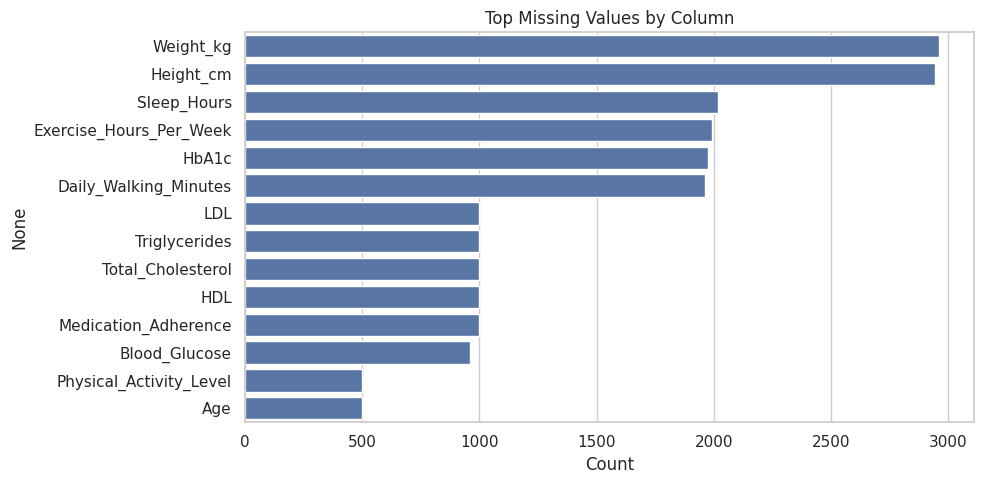

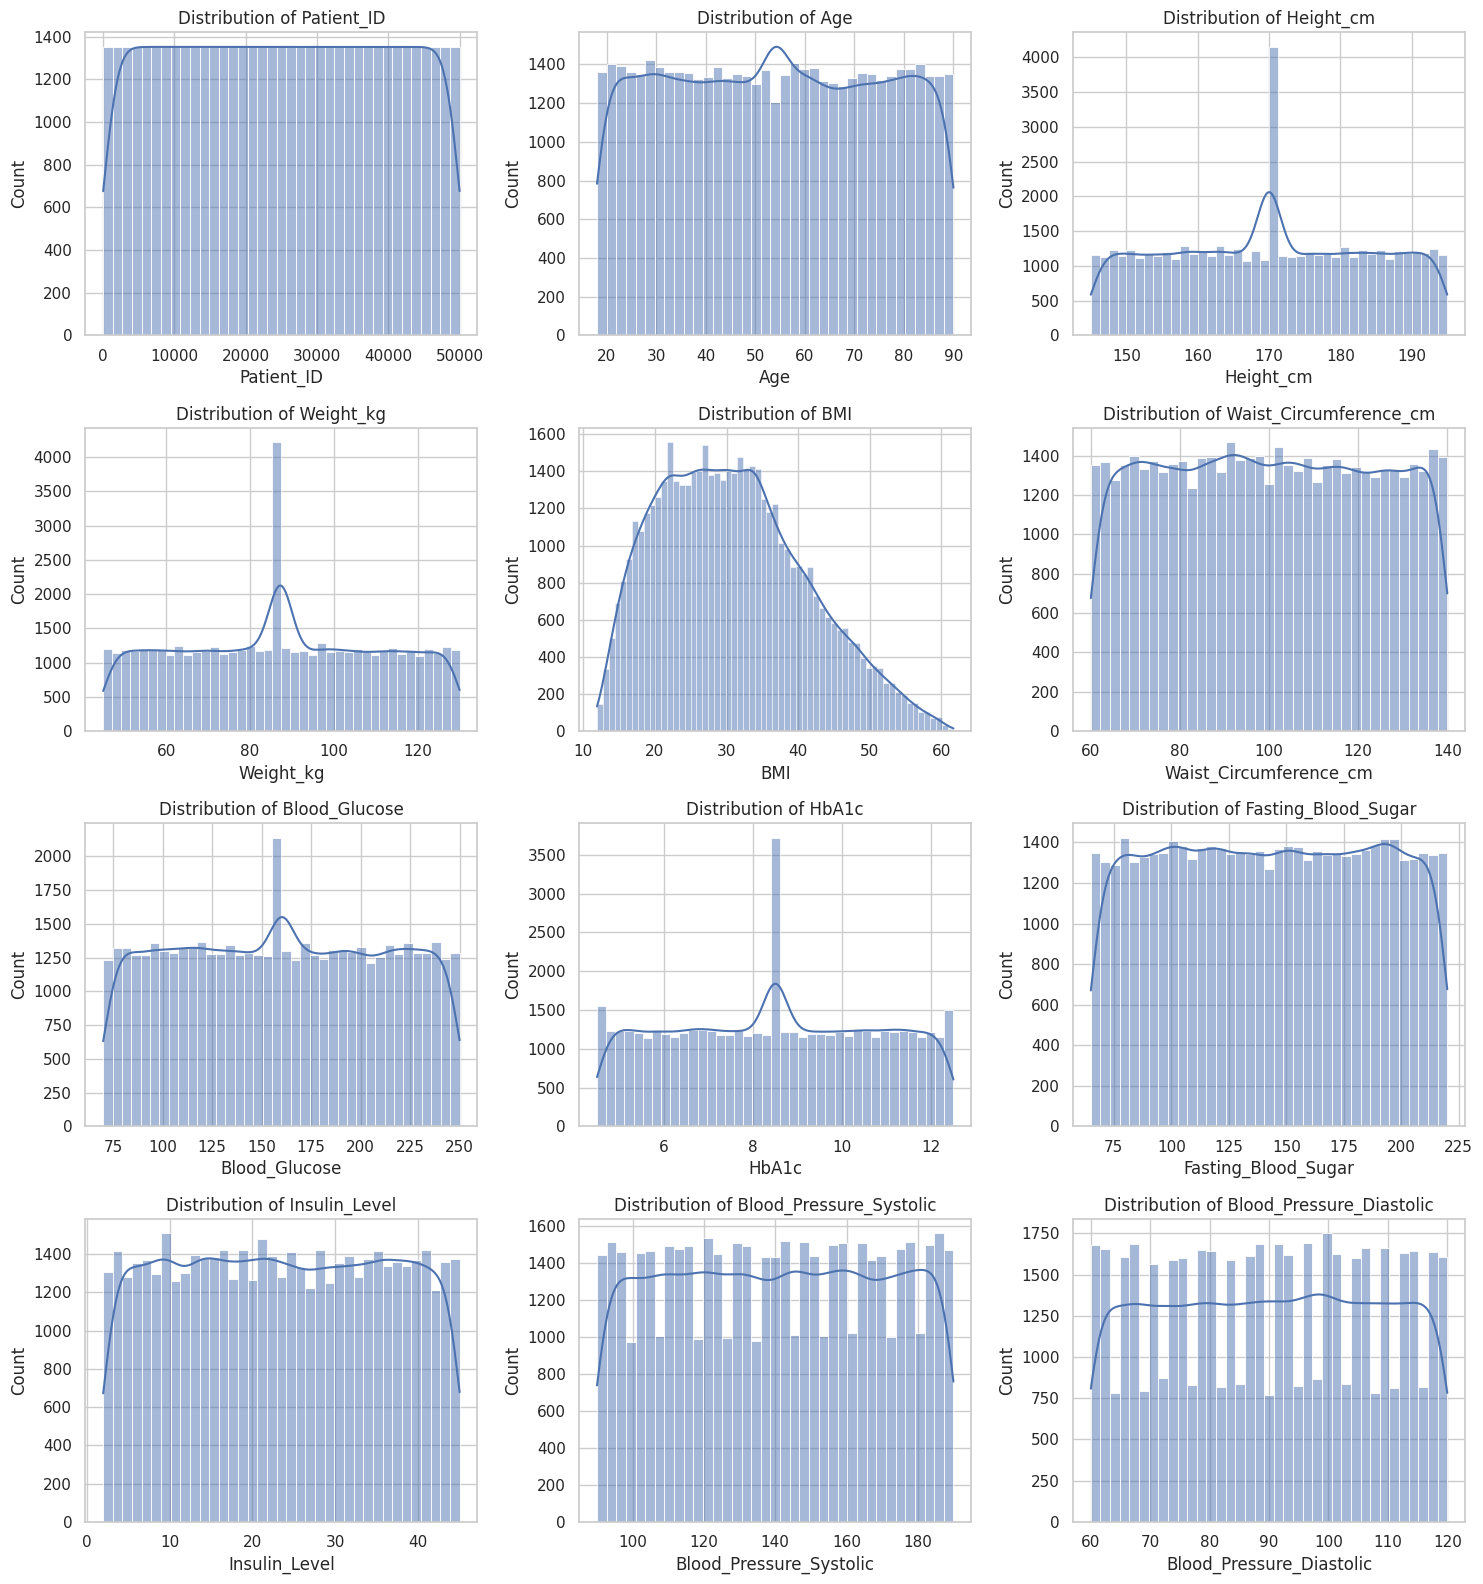

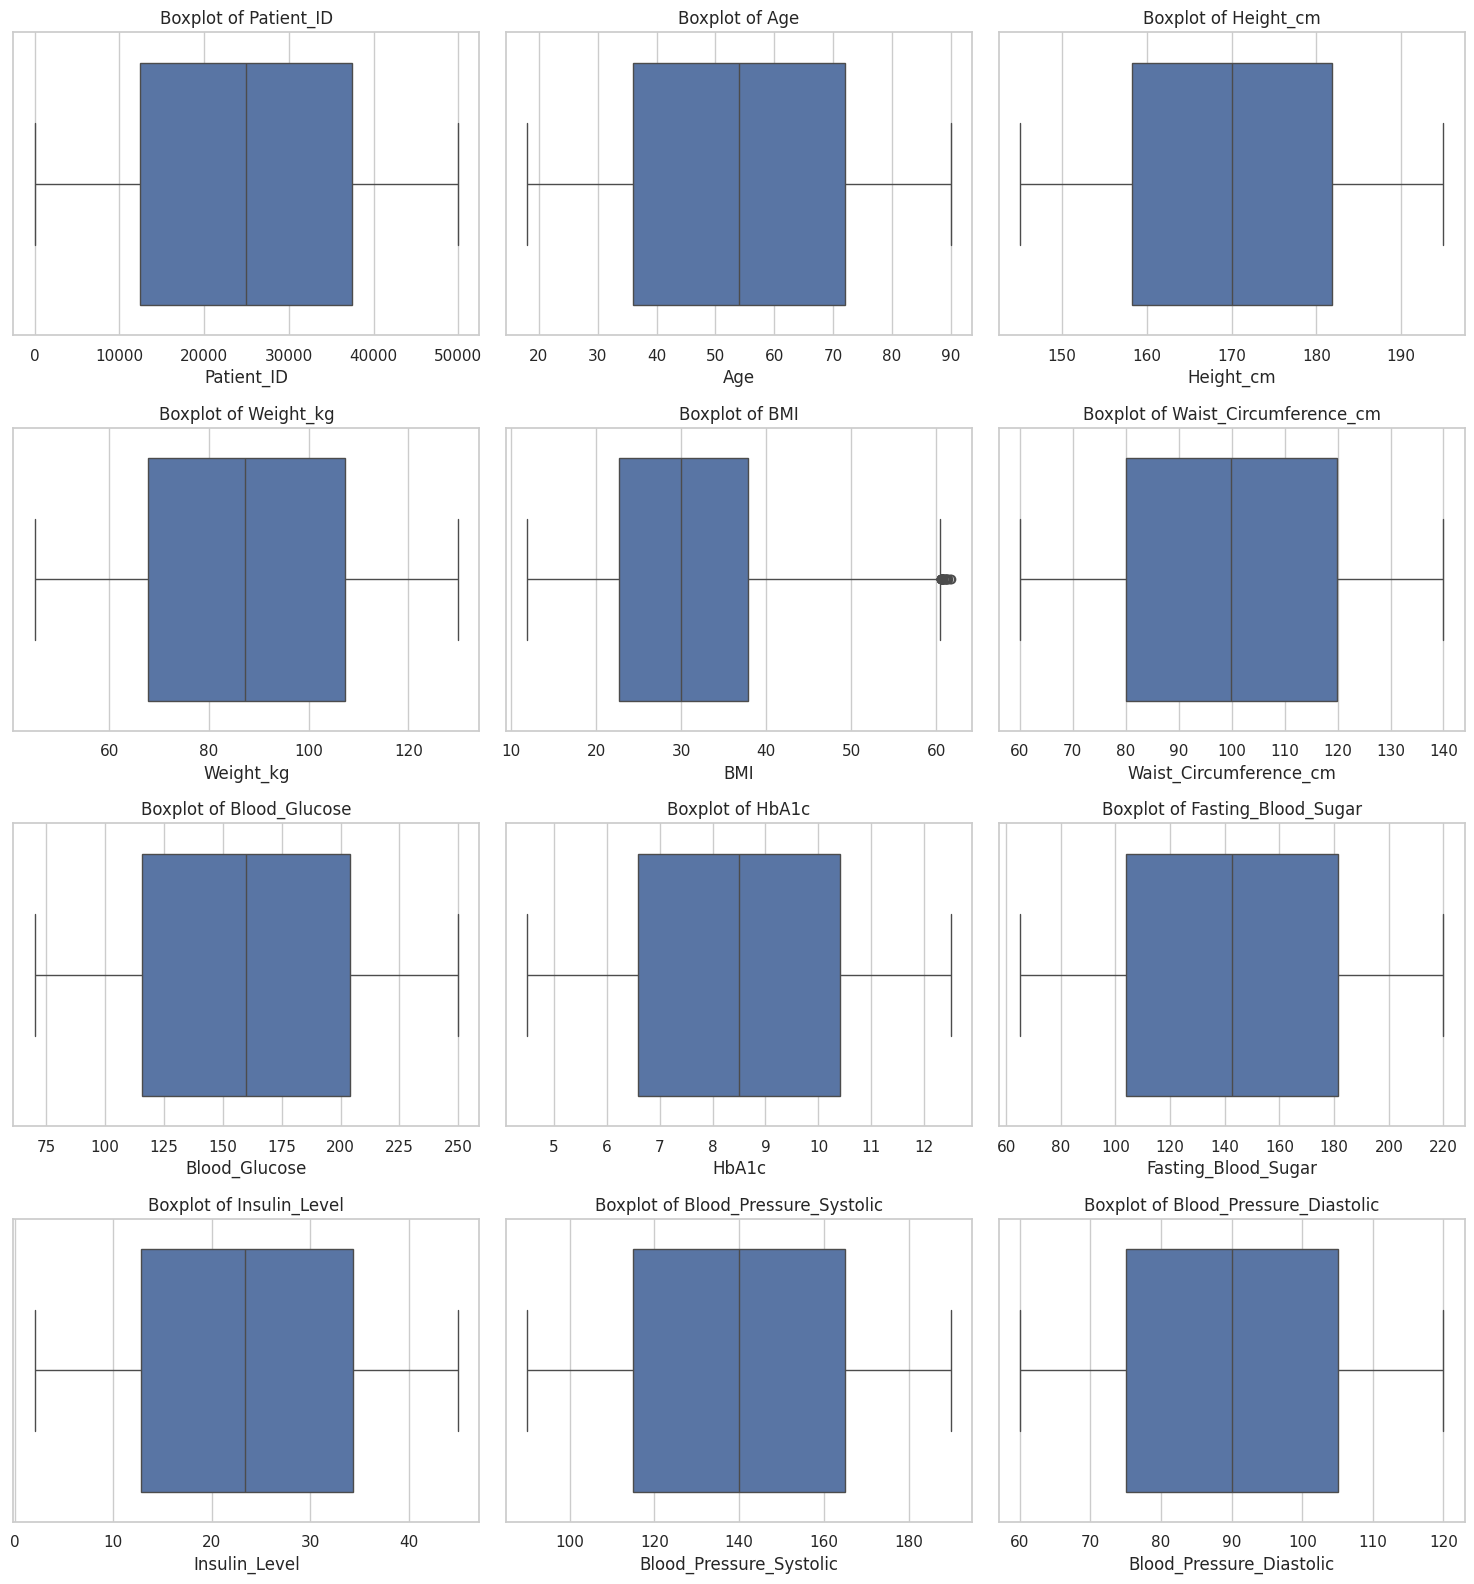

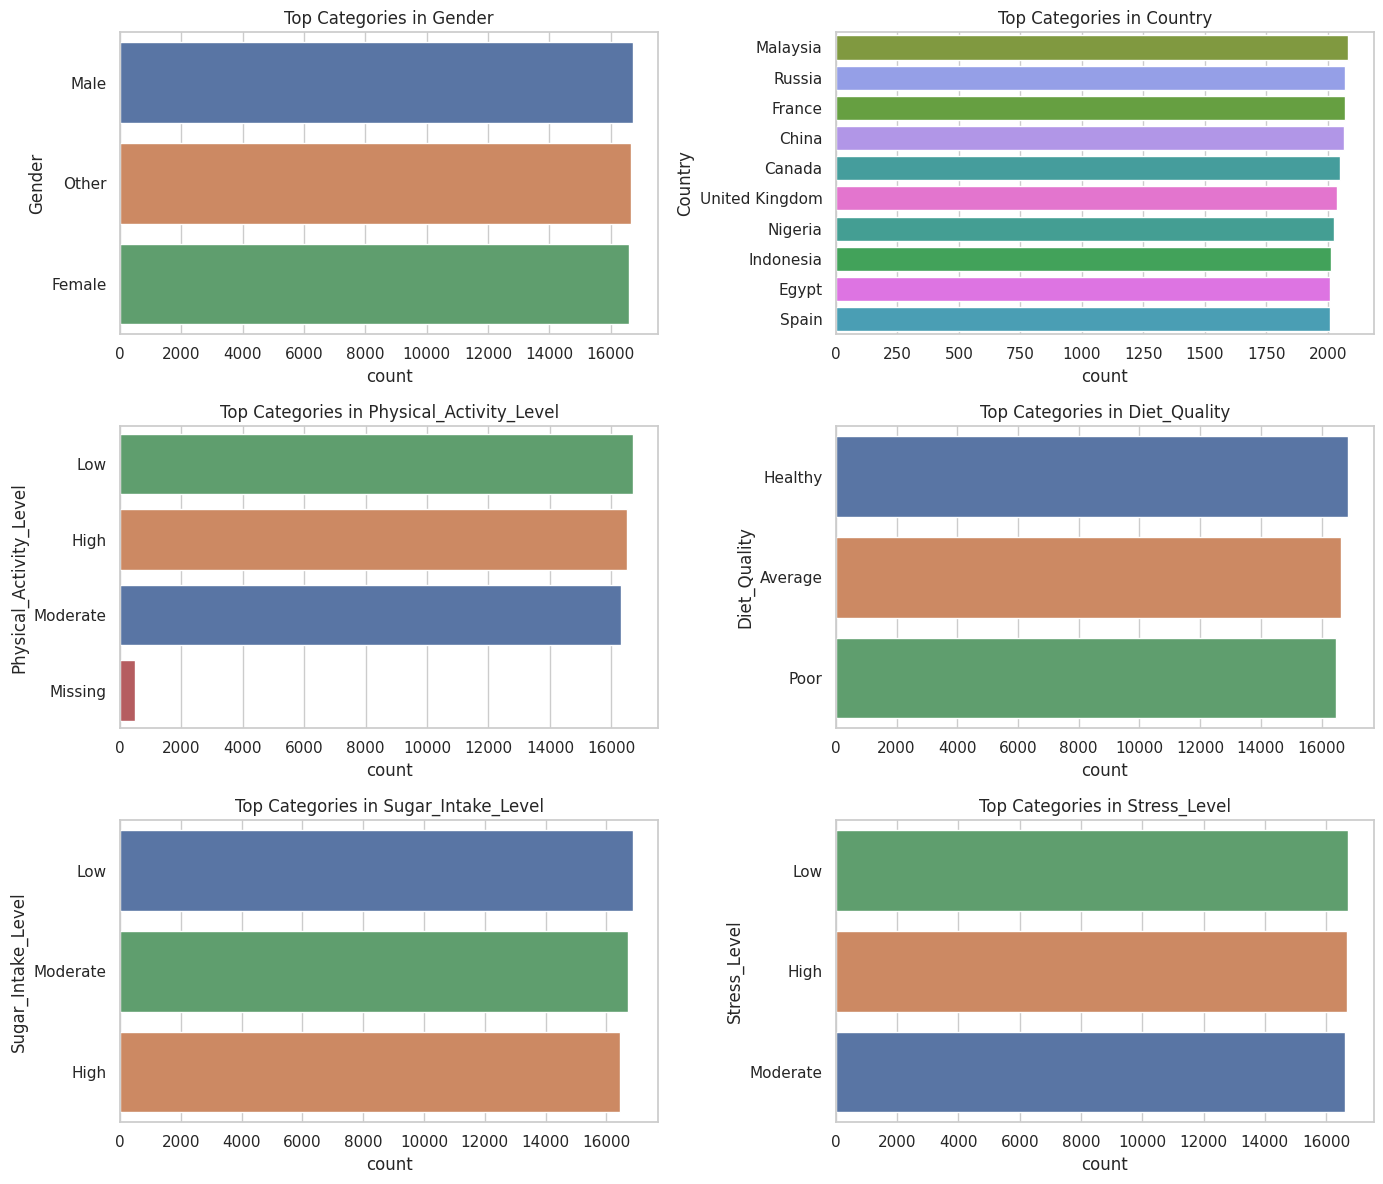

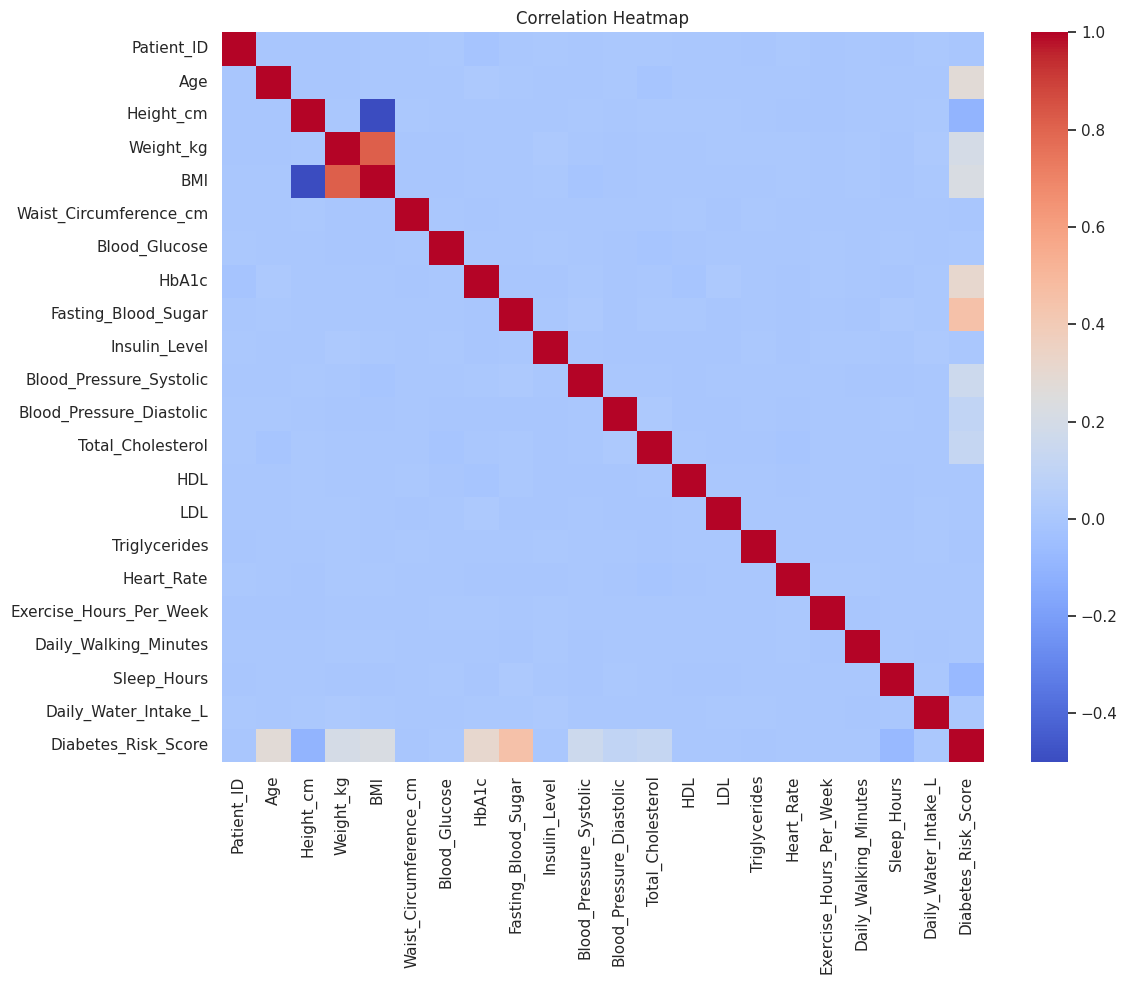


--- FINAL SUMMARY ---
Original Shape: (50000, 41)
Cleaned Shape: (50000, 115)
Duplicates Removed: 0
Remaining Missing Values: 0

Cleaned Dataset Head:
   Patient_ID   Age Gender        Country  Height_cm  Weight_kg   BMI  \
0           1  32.0   Male         Mexico      182.1       65.8  19.8   
1           2  42.0  Other   Saudi Arabia      148.5      101.2  45.9   
2           3  89.0  Other      Argentina      158.1       87.3  37.9   
3           4  87.0  Other  United States      190.9       95.9  26.3   
4           5  27.0  Other      Australia      156.9      101.9  41.4   

   Waist_Circumference_cm  Blood_Glucose  HbA1c  ...  Work_Type__len  \
0                    71.2           88.4   10.4  ...               7   
1                   121.8          247.3   11.3  ...              10   
2                   131.8          141.9    6.3  ...              10   
3                    99.1           90.1    7.4  ...               8   
4                    77.1           93.8   12.0  

In [ ]:
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# A) Imports + Config
warnings.filterwarnings('ignore')
np.random.seed(42)

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10
sns.set_theme(style="whitegrid")

DATASET_NAME = "mobeenfatimah/diabetes-risk-prediction-dataset-50k-patients"
EXACT_COLUMNS = [
    'Patient_ID', 'Age', 'Gender', 'Country', 'Height_cm', 'Weight_kg', 'BMI',
    'Waist_Circumference_cm', 'Blood_Glucose', 'HbA1c', 'Fasting_Blood_Sugar',
    'Insulin_Level', 'Blood_Pressure_Systolic', 'Blood_Pressure_Diastolic',
    'Total_Cholesterol', 'HDL', 'LDL', 'Triglycerides', 'Heart_Rate',
    'Physical_Activity_Level', 'Exercise_Hours_Per_Week', 'Daily_Walking_Minutes',
    'Diet_Quality', 'Sugar_Intake_Level', 'Sleep_Hours', 'Stress_Level',
    'Smoking_Status', 'Alcohol_Consumption', 'Family_History_Diabetes',
    'Hypertension', 'Heart_Disease', 'Fatty_Liver', 'PCOS',
    'Medication_Adherence', 'Work_Type', 'Residence_Type',
    'Daily_Water_Intake_L', 'Diabetes_Risk_Score', 'AI_Health_Recommendation',
    'Doctor_Consultation_Needed', 'Diabetes_Risk'
]
TARGET_COL = 'Diabetes_Risk'

# I) Helper Functions
def safe_read_csv(filepath):
    try:
        df = pd.read_csv(filepath)
        print(f"Successfully loaded dataset from {filepath}")
        return df
    except Exception as e:
        print(f"Error loading CSV from {filepath}: {e}")
        return pd.DataFrame()

def audit_missingness(df):
    try:
        null_counts = df.isnull().sum()
        null_pct = (null_counts / len(df)) * 100
        audit_df = pd.DataFrame({'Missing_Count': null_counts, 'Missing_Pct': null_pct})
        return audit_df[audit_df['Missing_Count'] > 0].sort_values(by='Missing_Pct', ascending=False)
    except Exception as e:
        print(f"Error auditing missingness: {e}")
        return pd.DataFrame()

def detect_column_types(df):
    num_cols, cat_cols, dt_cols = [], [], []
    for col in df.columns:
        if pd.api.types.is_datetime64_any_dtype(df[col]):
            dt_cols.append(col)
        elif pd.api.types.is_numeric_dtype(df[col]):
            num_cols.append(col)
        else:
            cat_cols.append(col)
    return num_cols, cat_cols, dt_cols

def safe_to_numeric(series):
    try:
        return pd.to_numeric(series, errors='coerce')
    except Exception:
        return series

def safe_to_datetime(series):
    try:
        return pd.to_datetime(series, errors='coerce')
    except Exception:
        return series

def plot_missingness(df):
    try:
        null_series = df.isnull().sum()
        null_series = null_series[null_series > 0].sort_values(ascending=False).head(30)
        if not null_series.empty:
            plt.figure(figsize=(10, 5))
            sns.barplot(x=null_series.values, y=null_series.index)
            plt.title("Top Missing Values by Column")
            plt.xlabel("Count")
            plt.tight_layout()
            plt.show()
        else:
            print("No missing values detected for missingness plot.")
    except Exception as e:
        print(f"Error plotting missingness: {e}")

def plot_histograms(df, num_cols, max_cols=12):
    try:
        cols_to_plot = num_cols[:max_cols]
        if cols_to_plot:
            fig, axes = plt.subplots(int(np.ceil(len(cols_to_plot) / 3)), 3, figsize=(15, 4 * int(np.ceil(len(cols_to_plot) / 3))))
            axes = axes.flatten() if len(cols_to_plot) > 1 else [axes]
            for i, col in enumerate(cols_to_plot):
                sns.histplot(df[col].dropna(), kde=True, ax=axes[i])
                axes[i].set_title(f"Distribution of {col}")
            for j in range(i + 1, len(axes)):
                fig.delaxes(axes[j])
            plt.tight_layout()
            plt.show()
    except Exception as e:
        print(f"Error plotting histograms: {e}")

def plot_boxplots(df, num_cols, max_cols=12):
    try:
        cols_to_plot = num_cols[:max_cols]
        if cols_to_plot:
            fig, axes = plt.subplots(int(np.ceil(len(cols_to_plot) / 3)), 3, figsize=(15, 4 * int(np.ceil(len(cols_to_plot) / 3))))
            axes = axes.flatten() if len(cols_to_plot) > 1 else [axes]
            for i, col in enumerate(cols_to_plot):
                sns.boxplot(x=df[col].dropna(), ax=axes[i])
                axes[i].set_title(f"Boxplot of {col}")
            for j in range(i + 1, len(axes)):
                fig.delaxes(axes[j])
            plt.tight_layout()
            plt.show()
    except Exception as e:
        print(f"Error plotting boxplots: {e}")

def plot_countplots(df, cat_cols, max_cols=6):
    try:
        cols_to_plot = cat_cols[:max_cols]
        if cols_to_plot:
            fig, axes = plt.subplots(int(np.ceil(len(cols_to_plot) / 2)), 2, figsize=(14, 4 * int(np.ceil(len(cols_to_plot) / 2))))
            axes = axes.flatten() if len(cols_to_plot) > 1 else [axes]
            for i, col in enumerate(cols_to_plot):
                order = df[col].value_counts().iloc[:10].index
                sns.countplot(y=df[col], order=order, ax=axes[i], hue=df[col], legend=False)
                axes[i].set_title(f"Top Categories in {col}")
            for j in range(i + 1, len(axes)):
                fig.delaxes(axes[j])
            plt.tight_layout()
            plt.show()
    except Exception as e:
        print(f"Error plotting countplots: {e}")

def plot_correlation_heatmap(df, num_cols):
    try:
        cols_to_corr = num_cols[:50]
        if len(cols_to_corr) > 1:
            corr = df[cols_to_corr].corr()
            plt.figure(figsize=(12, 10))
            sns.heatmap(corr, cmap="coolwarm", annot=False, fmt=".2f")
            plt.title("Correlation Heatmap")
            plt.tight_layout()
            plt.show()
    except Exception as e:
        print(f"Error plotting correlation heatmap: {e}")

def plot_datetime(df, dt_cols):
    try:
        for col in dt_cols:
            plt.figure(figsize=(10, 4))
            df[col].dt.to_period('M').value_counts().sort_index().plot(kind='line')
            plt.title(f"Frequency of {col} over time")
            plt.tight_layout()
            plt.show()
    except Exception as e:
        print(f"Error plotting datetime series: {e}")

# B) Load + Validate
try:
    df = safe_read_csv(DATA_DIR)
except NameError:
    print("DATA_DIR is not defined. Please define DATA_DIR.")
    df = pd.DataFrame()

if not df.empty:
    actual_cols = set(df.columns)
    expected_cols = set(EXACT_COLUMNS) if EXACT_COLUMNS else actual_cols
    missing_in_data = expected_cols - actual_cols
    extra_in_data = actual_cols - expected_cols
    print(f"Dataset Name: {DATASET_NAME}")
    print(f"Missing expected columns: {missing_in_data}")
    print(f"Extra columns present: {extra_in_data}")

    # C) Data Audit
    print("\n--- DATA AUDIT ---")
    print(f"Shape: {df.shape}")
    print(f"Memory Usage: {df.memory_usage(deep=True).sum() / 1e6:.2f} MB")
    print(f"Duplicate Rows: {df.duplicated().sum()}")
    print("\nMissing Value Audit:")
    print(audit_missingness(df))

    num_cols, cat_cols, dt_cols = detect_column_types(df)

    print(f"\nCategorical Cardinality:")
    for c in cat_cols:
        print(f"  {c}: {df[c].nunique()} unique values")

    print(f"\nConstant / Near-Constant Numerics:")
    for n in num_cols:
        std_val = df[n].std()
        if pd.isna(std_val) or std_val == 0:
            print(f"  {n} is constant or all-null")

    # D) ETL
    df_clean = df.copy()

    # Strip whitespace & unify null tokens for string columns
    for c in df_clean.select_dtypes(include='object').columns:
        df_clean[c] = df_clean[c].astype(str).str.strip()
        df_clean[c] = df_clean[c].replace(['nan', 'NaN', 'NULL', 'null', 'None', '', '?', 'NA'], np.nan)

    # Attempt numeric conversions on string columns
    for c in df_clean.select_dtypes(include='object').columns:
        converted = pd.to_numeric(df_clean[c], errors='coerce')
        if converted.notna().sum() > 0.5 * len(df_clean):
            df_clean[c] = converted

    # Safe Datetime Detection & Conversion
    for c in df_clean.select_dtypes(include='object').columns:
        try:
            converted_dt = pd.to_datetime(df_clean[c], errors='coerce')
            if converted_dt.notna().sum() > 0.5 * len(df_clean):
                df_clean[c] = converted_dt
        except Exception:
            pass

    # Drop duplicates
    duplicates_count = df_clean.duplicated().sum()
    df_clean = df_clean.drop_duplicates()

    num_cols, cat_cols, dt_cols = detect_column_types(df_clean)

    # Missing value handling & indicators
    for c in df_clean.columns:
        if df_clean[c].isnull().sum() > 0:
            df_clean[f"{c}__was_missing"] = df_clean[c].isnull().astype(int)
            if c in num_cols:
                median_val = df_clean[c].median()
                df_clean[c] = df_clean[c].fillna(median_val)
            elif c in cat_cols:
                df_clean[c] = df_clean[c].fillna("Missing")

    # IQR Outlier Detection & Winsorization into new columns
    for c in num_cols:
        Q1 = df_clean[c].quantile(0.25)
        Q3 = df_clean[c].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df_clean[f"{c}__winsor"] = np.clip(df_clean[c], lower_bound, upper_bound)

    # E) EDA
    print("\n--- EDA SUMMARY ---")
    print("\nNumeric Summary Statistics:")
    num_summary = pd.DataFrame({
        'Mean': df_clean[num_cols].mean(),
        'Std': df_clean[num_cols].std(),
        'Skewness': df_clean[num_cols].skew(),
        'Kurtosis': df_clean[num_cols].kurtosis()
    })
    print(num_summary)

    print("\nCategorical Top Frequencies:")
    for c in cat_cols[:5]:
        print(f"\nColumn: {c}")
        print(df_clean[c].value_counts().head(5))

    # Correlations
    if len(num_cols) > 1:
        pearson_corr = df_clean[num_cols].corr(method='pearson')
        spearman_corr = df_clean[num_cols].corr(method='spearman')

        high_corr_pairs = []
        for i in range(len(num_cols)):
            for j in range(i+1, len(num_cols)):
                c1, c2 = num_cols[i], num_cols[j]
                val = pearson_corr.loc[c1, c2]
                if abs(val) >= 0.85:
                    high_corr_pairs.append((c1, c2, val))

        print("\nHighly Correlated Pairs (|r| >= 0.85):")
        for pair in high_corr_pairs:
            print(f"  {pair[0]} & {pair[1]}: r = {pair[2]:.4f}")

    # Target-Aware Analysis
    if TARGET_COL and TARGET_COL in df_clean.columns:
        print(f"\n--- TARGET ANALYSIS ({TARGET_COL}) ---")
        print(df_clean[TARGET_COL].value_counts(dropna=False))

    # F) Visualization
    print("\n--- GENERATING VISUALIZATIONS ---")
    plot_missingness(df)
    plot_histograms(df_clean, num_cols)
    plot_boxplots(df_clean, num_cols)
    plot_countplots(df_clean, cat_cols)
    plot_correlation_heatmap(df_clean, num_cols)
    if dt_cols:
        plot_datetime(df_clean, dt_cols)

    # G) Feature Engineering
    for c in dt_cols:
        df_clean[f"{c}__year"] = df_clean[c].dt.year
        df_clean[f"{c}__month"] = df_clean[c].dt.month
        df_clean[f"{c}__dayofweek"] = df_clean[c].dt.dayofweek

    for c in cat_cols:
        if c in df_clean.columns:
            str_series = df_clean[c].astype(str)
            df_clean[f"{c}__len"] = str_series.str.len()
            df_clean[f"{c}__words"] = str_series.str.split().str.len()

    # H) Final Summary
    print("\n--- FINAL SUMMARY ---")
    print(f"Original Shape: {df.shape}")
    print(f"Cleaned Shape: {df_clean.shape}")
    print(f"Duplicates Removed: {duplicates_count}")
    print(f"Remaining Missing Values: {df_clean.isnull().sum().sum()}")
    print("\nCleaned Dataset Head:")
    print(df_clean.head())


Upload file dataset CSV kamu.


Saving diabetes_risk_prediction_dataset.csv to diabetes_risk_prediction_dataset (1).csv

Dataset berhasil dibaca!
Nama file: diabetes_risk_prediction_dataset (1).csv
Ukuran dataset: (50000, 41)

Daftar kolom:
['Patient_ID', 'Age', 'Gender', 'Country', 'Height_cm', 'Weight_kg', 'BMI', 'Waist_Circumference_cm', 'Blood_Glucose', 'HbA1c', 'Fasting_Blood_Sugar', 'Insulin_Level', 'Blood_Pressure_Systolic', 'Blood_Pressure_Diastolic', 'Total_Cholesterol', 'HDL', 'LDL', 'Triglycerides', 'Heart_Rate', 'Physical_Activity_Level', 'Exercise_Hours_Per_Week', 'Daily_Walking_Minutes', 'Diet_Quality', 'Sugar_Intake_Level', 'Sleep_Hours', 'Stress_Level', 'Smoking_Status', 'Alcohol_Consumption', 'Family_History_Diabetes', 'Hypertension', 'Heart_Disease', 'Fatty_Liver', 'PCOS', 'Medication_Adherence', 'Work_Type', 'Residence_Type', 'Daily_Water_Intake_L', 'Diabetes_Risk_Score', 'AI_Health_Recommendation', 'Doctor_Consultation_Needed', 'Diabetes_Risk']


,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,...,Fatty_Liver,PCOS,Medication_Adherence,Work_Type,Residence_Type,Daily_Water_Intake_L,Diabetes_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Diabetes_Risk
0,1,32.0,Male,Mexico,182.1,65.8,19.8,71.2,88.4,10.4,...,Yes,No,Good,Retired,Rural,4.4,60,Healthy Diet Plan,Yes,Moderate
1,2,42.0,Other,Saudi Arabia,148.5,101.2,45.9,121.8,247.3,11.3,...,Yes,Yes,Average,Government,Rural,2.1,99,Begin Diabetes Management Plan,Yes,High
2,3,89.0,Other,Argentina,158.1,NaN,37.9,131.8,141.9,6.3,...,Yes,No,Average,Government,Urban,2.8,80,Strict Blood Sugar Monitoring,Yes,High
3,4,87.0,Other,United States,190.9,95.9,26.3,99.1,90.1,7.4,...,No,No,Average,Business,Rural,1.5,82,Begin Diabetes Management Plan,Yes,High
4,5,27.0,Other,Australia,156.9,101.9,41.4,77.1,93.8,12.0,...,Yes,Yes,Poor,Private,Rural,1.6,93,Begin Diabetes Management Plan,Yes,High



Distribusi target:


,Jumlah
Diabetes_Risk,
High,36593
Moderate,12937
Low,470



Jumlah fitur yang digunakan: 36
Fitur yang dikecualikan: ['Diabetes_Risk', 'Patient_ID', 'Diabetes_Risk_Score', 'AI_Health_Recommendation', 'Doctor_Consultation_Needed']
Fitur yang digunakan:
['Age', 'Gender', 'Country', 'Height_cm', 'Weight_kg', 'BMI', 'Waist_Circumference_cm', 'Blood_Glucose', 'HbA1c', 'Fasting_Blood_Sugar', 'Insulin_Level', 'Blood_Pressure_Systolic', 'Blood_Pressure_Diastolic', 'Total_Cholesterol', 'HDL', 'LDL', 'Triglycerides', 'Heart_Rate', 'Physical_Activity_Level', 'Exercise_Hours_Per_Week', 'Daily_Walking_Minutes', 'Diet_Quality', 'Sugar_Intake_Level', 'Sleep_Hours', 'Stress_Level', 'Smoking_Status', 'Alcohol_Consumption', 'Family_History_Diabetes', 'Hypertension', 'Heart_Disease', 'Fatty_Liver', 'PCOS', 'Medication_Adherence', 'Work_Type', 'Residence_Type', 'Daily_Water_Intake_L']

Fitur numerik: 20
Fitur kategorikal: 16

Jumlah data training: 40000
Jumlah data testing: 10000

Sedang melatih: Logistic Regression

Sedang melatih: Random Forest
Accuracy : 0.902

,Accuracy,Precision,Recall,F1-score
Random Forest,0.902,0.9019,0.902,0.8938



Model terpilih: Random Forest


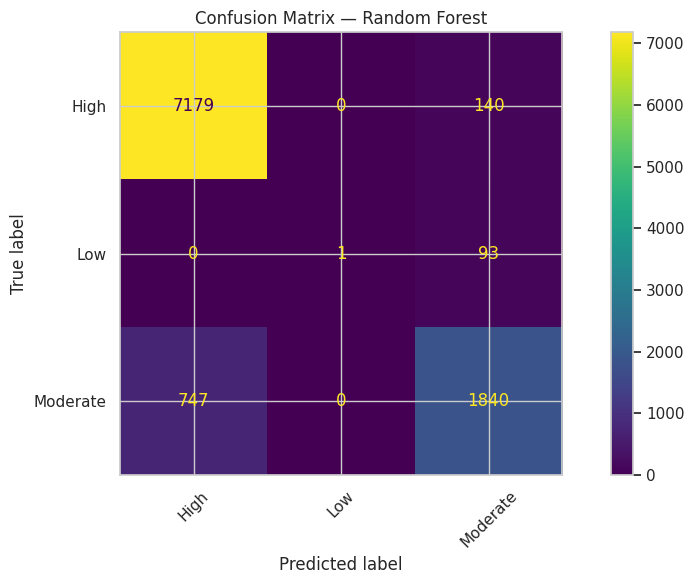


TRAINING SELESAI
Model terbaik: Random Forest
Model: /content/artifacts/diabetes_model.joblib
Metadata: /content/artifacts/metrics.json


<Figure size 1000x600 with 0 Axes>

In [ ]:
# ============================================================
# AI HEALTH INSIGHT
# Diabetes Risk Classification — Google Colab
# ============================================================

import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
accuracy_score,
precision_score,
recall_score,
f1_score,
classification_report,
confusion_matrix,
ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

# ============================================================
# 1. UPLOAD DATASET
# ============================================================

print("Upload file dataset CSV kamu.")
uploaded = files.upload()

csv_files = [name for name in uploaded if name.lower().endswith(".csv")]

if not csv_files:
  raise ValueError("File CSV tidak ditemukan. Upload dataset berformat .csv.")

file_path = csv_files[0]
df = pd.read_csv(file_path)

print("\nDataset berhasil dibaca!")
print("Nama file:", file_path)
print("Ukuran dataset:", df.shape)

print("\nDaftar kolom:")
print(df.columns.tolist())

display(df.head())

# ============================================================
# 2. TENTUKAN TARGET
# ============================================================

TARGET = "Diabetes_Risk"

if TARGET not in df.columns:
  raise ValueError(
f"Kolom target '{TARGET}' tidak ditemukan.\n"
f"Kolom tersedia: {df.columns.tolist()}"
)

df = df.dropna(subset=[TARGET]).copy()

print("\nDistribusi target:")
display(df[TARGET].value_counts(dropna=False).to_frame("Jumlah"))

if df[TARGET].nunique() < 2:
  raise ValueError("Target hanya memiliki satu kelas. Training tidak dapat dilakukan.")

# ============================================================
# 3. PILIH FITUR
# ============================================================

# Kolom yang tidak boleh digunakan sebagai fitur:
# - ID pasien
# - Skor risiko yang mungkin dibuat dari label
# - Rekomendasi atau keputusan yang mungkin dibuat dari label
# - Kolom target itu sendiri

excluded_columns = [
TARGET,
"Patient_ID",
"Diabetes_Risk_Score",
"AI_Health_Recommendation",
"Doctor_Consultation_Needed"
]

# Hanya kecualikan kolom yang benar-benar ada
excluded_columns = [
col for col in excluded_columns if col in df.columns
]

X = df.drop(columns=excluded_columns).copy()
y = df[TARGET].astype(str).str.strip()

# Buang fitur yang kosong seluruhnya
X = X.dropna(axis=1, how="all")

if X.shape[1] == 0:
  raise ValueError("Tidak ada fitur tersisa untuk training.")

# Hapus fitur konstan yang tidak memberi informasi
constant_cols = [
col for col in X.columns if X[col].nunique(dropna=True) <= 1
]
X = X.drop(columns=constant_cols)

# Hapus baris fitur duplikat bukan langkah wajib; biarkan data tetap utuh.
print("\nJumlah fitur yang digunakan:", X.shape[1])
print("Fitur yang dikecualikan:", excluded_columns)
print("Fitur yang digunakan:")
print(X.columns.tolist())

# ============================================================
# 4. DETEKSI TIPE FITUR
# ============================================================

numeric_features = X.select_dtypes(
include=["number", "bool"]
).columns.tolist()

categorical_features = [
col for col in X.columns
if col not in numeric_features
]

print("\nFitur numerik:", len(numeric_features))
print("Fitur kategorikal:", len(categorical_features))

# ============================================================
# 5. PREPROCESSING
# ============================================================

numeric_transformer = Pipeline(steps=[
("imputer", SimpleImputer(strategy="median")),
("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
("imputer", SimpleImputer(strategy="most_frequent")),
("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
transformers=[
("numeric", numeric_transformer, numeric_features),
("categorical", categorical_transformer, categorical_features)
],
remainder="drop"
)

# ============================================================
# 6. SPLIT DATA TRAINING DAN TESTING
# ============================================================

class_counts = y.value_counts()

# Stratifikasi hanya memungkinkan jika tiap kelas punya minimal 2 data.
use_stratify = class_counts.min() >= 2

X_train, X_test, y_train, y_test = train_test_split(
X,
y,
test_size=0.2,
random_state=42,
stratify=y if use_stratify else None
)

print("\nJumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

# ============================================================
# 7. TRAINING MODEL
# ============================================================

models = {
"Logistic Regression": LogisticRegression(
max_iter=2000,
class_weight="balanced"
),
"Random Forest": RandomForestClassifier(
n_estimators=200,
min_samples_leaf=2,
class_weight="balanced",
random_state=42,
n_jobs=-1
)
}

trained_models = {}
results = {}

for model_name, classifier in models.items():

  print(f"\nSedang melatih: {model_name}")

pipeline = Pipeline(steps=[
("preprocessor", preprocessor),
("classifier", classifier)
])

pipeline.fit(X_train, y_train)

predictions = pipeline.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
precision = precision_score(
y_test, predictions,
average="weighted", zero_division=0
)
recall = recall_score(
y_test, predictions,
average="weighted", zero_division=0
)
f1 = f1_score(
y_test, predictions,
average="weighted", zero_division=0
)

trained_models[model_name] = pipeline

results[model_name] = {
"Accuracy": float(accuracy),
"Precision": float(precision),
"Recall": float(recall),
"F1-score": float(f1)
}

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification report:")
print(classification_report(
y_test, predictions, zero_division=0
))

# ============================================================
# 8. PERBANDINGAN MODEL
# ============================================================

results_df = pd.DataFrame(results).T

print("\nHASIL PERBANDINGAN MODEL")
display(results_df.round(4))

# Memilih model dengan F1-score weighted tertinggi
best_model_name = results_df["F1-score"].idxmax()
best_model = trained_models[best_model_name]

print("\nModel terpilih:", best_model_name)

# ============================================================
# 9. CONFUSION MATRIX
# ============================================================

best_predictions = best_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
y_test,
best_predictions,
xticks_rotation=45,
values_format="d"
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

# ============================================================
# 10. SIMPAN MODEL DAN METADATA
# ============================================================

os.makedirs("/content/artifacts", exist_ok=True)

model_path = "/content/artifacts/diabetes_model.joblib"
metrics_path = "/content/artifacts/metrics.json"

joblib.dump(best_model, model_path)

metadata = {
"project": "AI Health Insight",
"target_column": TARGET,
"best_model": best_model_name,
"feature_columns": X.columns.tolist(),
"numeric_columns": numeric_features,
"categorical_columns": categorical_features,
"excluded_columns": excluded_columns,
"class_labels": sorted(y.unique().tolist()),
"train_rows": int(len(X_train)),
"test_rows": int(len(X_test)),
"metrics": results
}

with open(metrics_path, "w", encoding="utf-8") as f:
  json.dump(metadata, f, indent=2)

# Simpan confusion matrix sebagai gambar
plt.figure()
ConfusionMatrixDisplay.from_predictions(
y_test,
best_predictions,
xticks_rotation=45,
values_format="d"
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.savefig(
"/content/artifacts/confusion_matrix.png",
dpi=160,
bbox_inches="tight"
)
plt.close()

print("\n====================================")
print("TRAINING SELESAI")
print("Model terbaik:", best_model_name)
print("Model:", model_path)
print("Metadata:", metrics_path)
print("====================================")
